# Generación de gráficas de resultados

Genera las figuras comparativas del informe a partir de las métricas e importancias guardadas en `resultados_clasificacion/` por [`modelos.ipynb`](modelos.ipynb). Las figuras se guardan en `figuras/`.

In [29]:
# Configuración: rutas, nombres de modelos, colores y métricas
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUTA_DATOS = "resultados_clasificacion"          
RUTA_FIGS  = "figuras"
os.makedirs(RUTA_FIGS, exist_ok=True)

MODELOS = ["logistic_regression", "decision_tree", "random_forest", "xgboost", "lightgbm"]

NOMBRES_MODELO = {
    "logistic_regression": "Regresión logística",
    "decision_tree":       "Árbol de decisión",
    "random_forest":       "Random Forest",
    "xgboost":             "XGBoost",
    "lightgbm":            "LightGBM",
}

meses = {
    1: 'Enero',
    2: 'Febrero',
    3: 'Marzo',
    4: 'Abril'
}


COLORES_MODELO = {
    "Regresión logística": "#0072B2",
    "Árbol de decisión":   "#E69F00",
    "Random Forest":       "#009E73",
    "XGBoost":             "#CC79A7",
    "LightGBM":            "#56B4E9",
}

METRICAS = {
    "accuracy":            "Accuracy",
    "auc_roc":             "AUC-ROC",
    "pr_auc":              "PR-AUC",
    "precision_aprobado":  "Precisión (aprob.)",
    "recall_aprobado":     "Recall (aprob.)",
    "f1_aprobado":         "F1 (aprob.)",
    "precision_reprobado": "Precisión (reprob.)",
    "recall_reprobado":    "Recall (reprob.)",
    "f1_reprobado":        "F1 (reprob.)",
    "f2_reprobado":        "F2 (reprob.)",
}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10,
})

## 1. Carga de datos

In [30]:
# Carga de métricas e importancias de clasificación
resultados = pd.concat(
    [pd.read_csv(os.path.join(RUTA_DATOS, f"resultados_{m}.csv")) for m in MODELOS],
    ignore_index=True,
)
importancias = pd.concat(
    [pd.read_csv(os.path.join(RUTA_DATOS, f"importancias_{m}.csv")) for m in MODELOS],
    ignore_index=True,
)

resultados["Modelo"]   = resultados["modelo"].map(NOMBRES_MODELO)
importancias["Modelo"] = importancias["modelo"].map(NOMBRES_MODELO)
ORDEN_MODELOS = [NOMBRES_MODELO[m] for m in MODELOS]

print(resultados.shape, importancias.shape)

(20, 37) (130, 7)


## 2. Comparación de modelos por mes
Graficamos, para cada mes, las métricas de la clase *reprobado* (la de interés) en el conjunto de prueba, usando el umbral que maximizó F2: F2, sensibilidad (*recall*), precisión y F1. El eje Y va de 0 a 1.05.

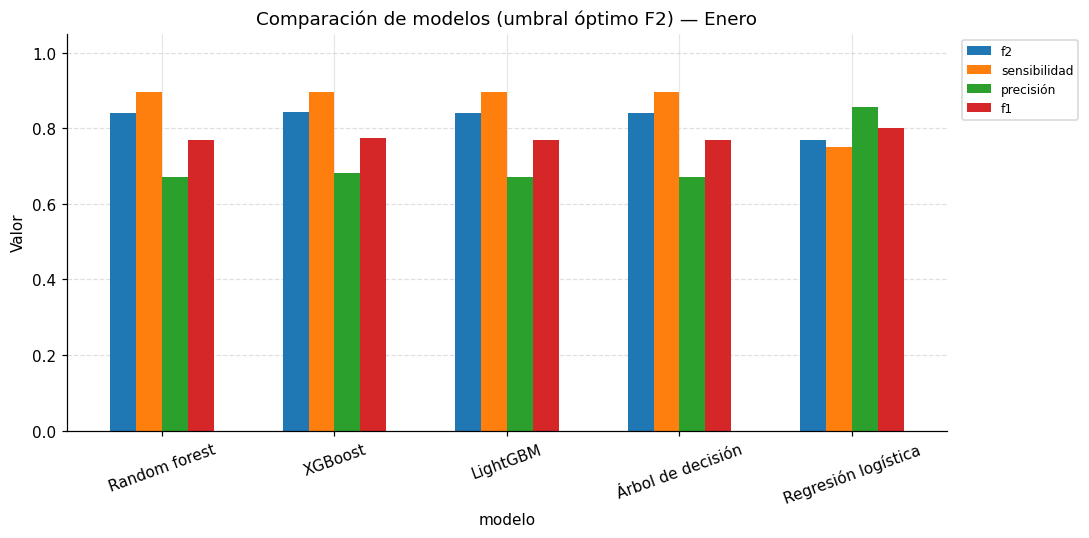

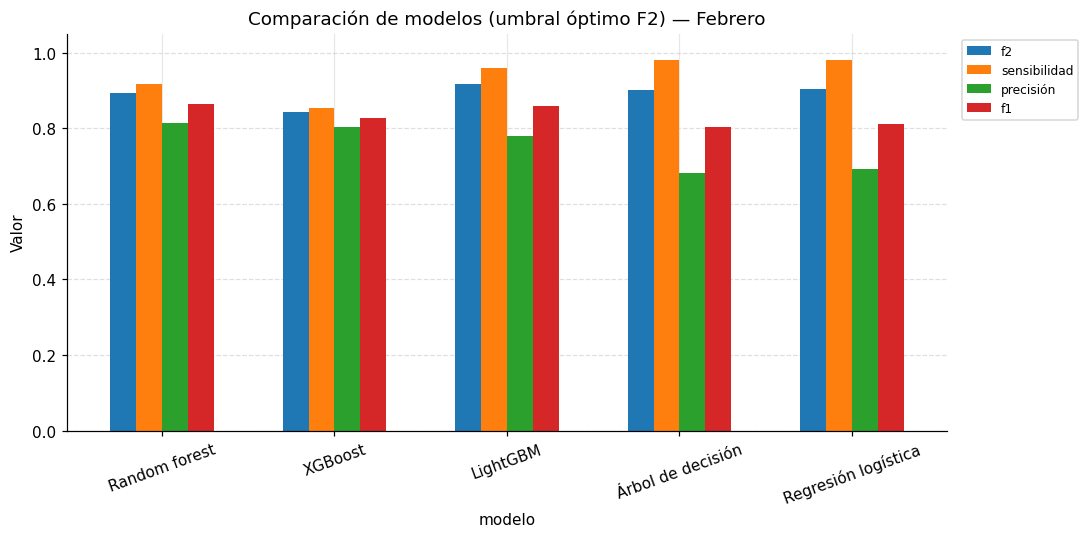

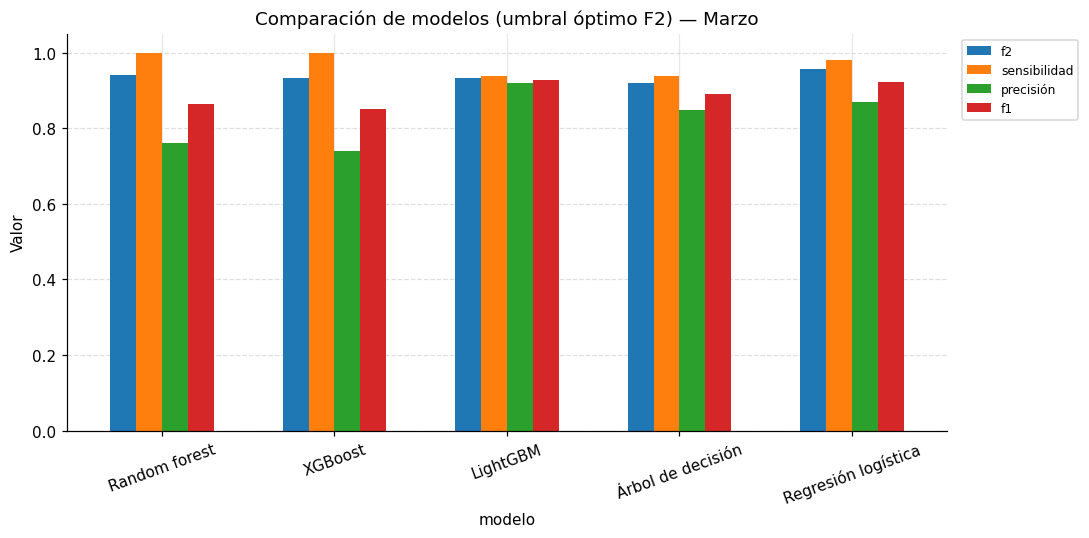

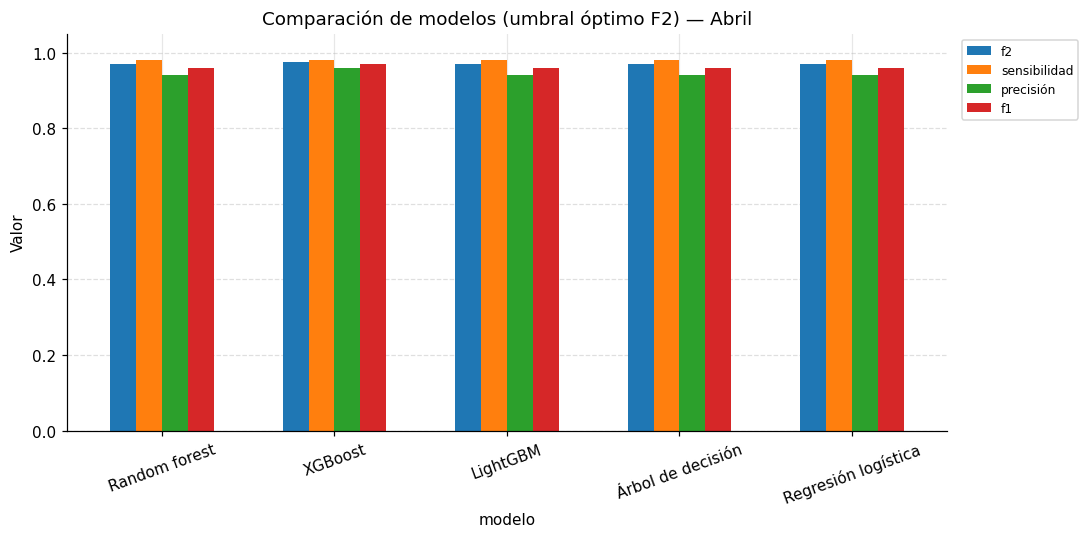

In [31]:
# Gráfica de barras de métricas por mes
METRICAS = {
    "f2_reprobado":     "f2",
    "recall_reprobado": "sensibilidad",
    "precision_reprobado":  "precisión",
    "f1_reprobado":     "f1",
}

MODELOS = {
    "random_forest":       "Random forest",
    "xgboost":             "XGBoost",
    "lightgbm":            "LightGBM",
    "decision_tree":       "Árbol de decisión",
    "logistic_regression": "Regresión logística",
}

resultados = pd.concat(
    [pd.read_csv(os.path.join(RUTA_DATOS, f"resultados_{m}.csv")) for m in MODELOS],
    ignore_index=True,
)
resultados["modelo"] = resultados["modelo"].map(MODELOS)

for mes in sorted(resultados["mes"].unique()):
    df_mes = (resultados[resultados["mes"] == mes]
              .set_index("modelo")
              .loc[list(MODELOS.values()), list(METRICAS)]
              .rename(columns=METRICAS))

    ax = df_mes.plot(kind="bar", figsize=(10, 5), width=0.6)
    ax.set_title(f"Comparación de modelos (umbral óptimo F2) — {meses[mes]}")
    ax.set_xlabel("modelo")
    ax.set_ylabel("Valor")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(os.path.join(RUTA_FIGS, f"comparacion_modelos_mes{mes}.png"),
                dpi=300, bbox_inches="tight")
    plt.show()

## 3. Importancia de variables

Las variables que dependen del mes (`porcentaje_acum_actividades_mes_k`, `delta_actividades_mes_k`,
`nota_examen_mes_k`) se agrupan con un nombre común para poder comparar entre meses:

- `porcentaje_acum_actividades_mes_k` → **% acumulado actividades**
- `delta_actividades_mes_k` → **Δ actividades**
- `nota_examen_mes_k` con *k = mes del modelo* → **Nota examen (mes actual)**
- `nota_examen_mes_k` con *k < mes del modelo* → **Nota examen (meses previos)** (se suman)

Se usa `importancia_norm` (suma 1 dentro de cada modelo-mes), así que las escalas son comparables
aunque cada modelo use un tipo distinto de importancia (impureza, ganancia o |coeficiente|).

In [32]:
# Agrupación de variables mensuales para comparar importancias
NOMBRES_VAR = {
    "veces_curso":        "Veces cursado",
    "PAA":                "PAA",
    "Colegio":            "Colegio",
    "Virtualidad":        "Virtualidad",
    "TituloNivelMedio":   "Título nivel medio",
    "DiferenciaPromedio": "Diferencia promedio",
}

def agrupar_variable(var, mes):
    """Agrupa las variables que dependen del mes bajo un nombre común"""
    if var.startswith("porcentaje_acum_actividades_mes_"):
        return "% acumulado actividades"
    if var.startswith("delta_actividades_mes_"):
        return "Δ actividades"
    if var.startswith("nota_examen_mes_"):
        k = int(var.rsplit("_", 1)[-1])
        return "Nota examen (mes actual)" if k == mes else "Nota examen (meses previos)"
    return NOMBRES_VAR.get(var, var)

importancias["Variable"] = [agrupar_variable(v, m) for v, m in zip(importancias["variable"], importancias["mes"])]

imp = (importancias
       .groupby(["Modelo", "mes", "Variable"], as_index=False)["importancia_norm"].sum())

# Tipo de importancia de cada modelo (para los títulos)
TIPO_IMP = importancias.groupby("Modelo")["tipo_importancia"].first().to_dict()
ETIQUETA_TIPO = {"impurity": "reducción de impureza", "gain": "ganancia", "abs_coef": "|coeficiente|"}

### 3.1 Importancia por modelo (un panel por mes)

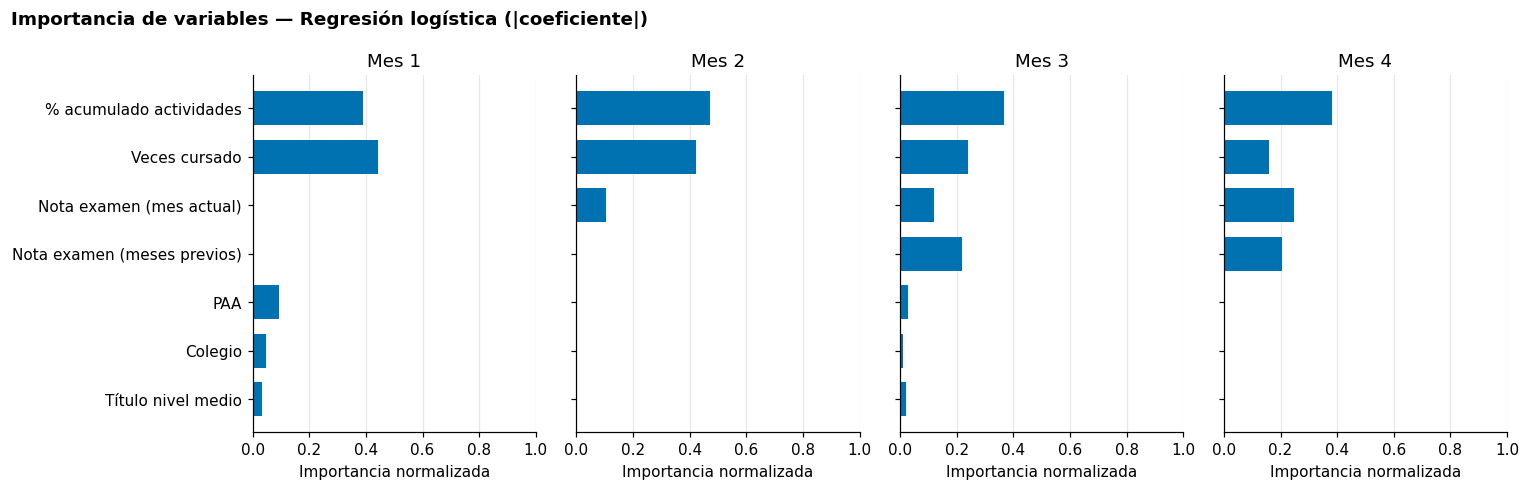

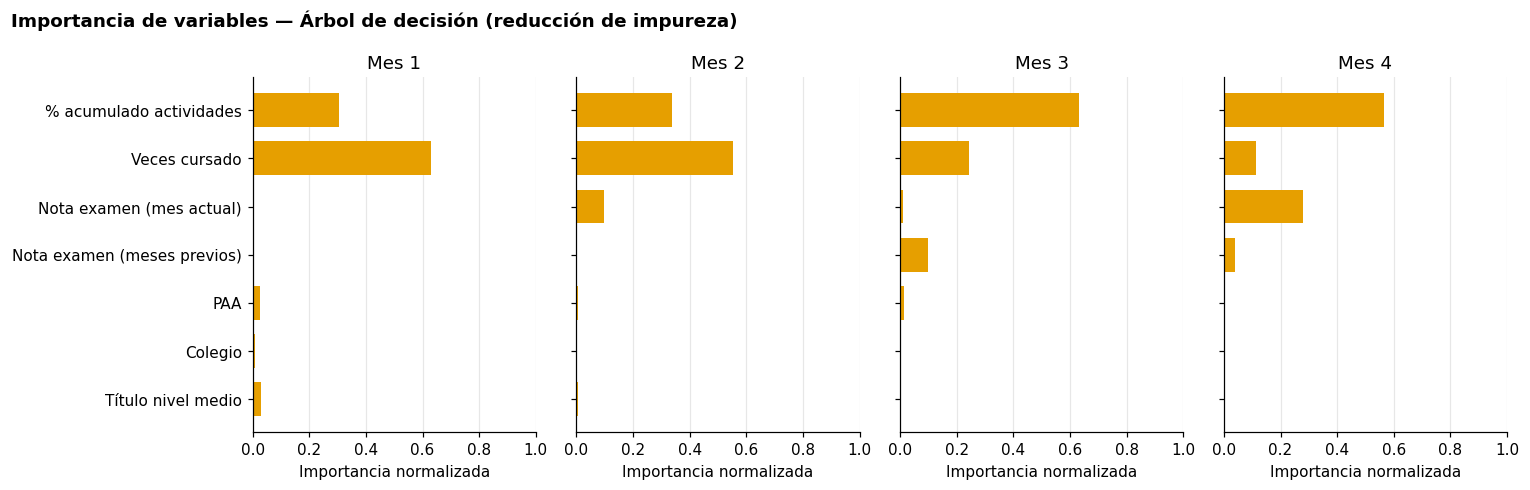

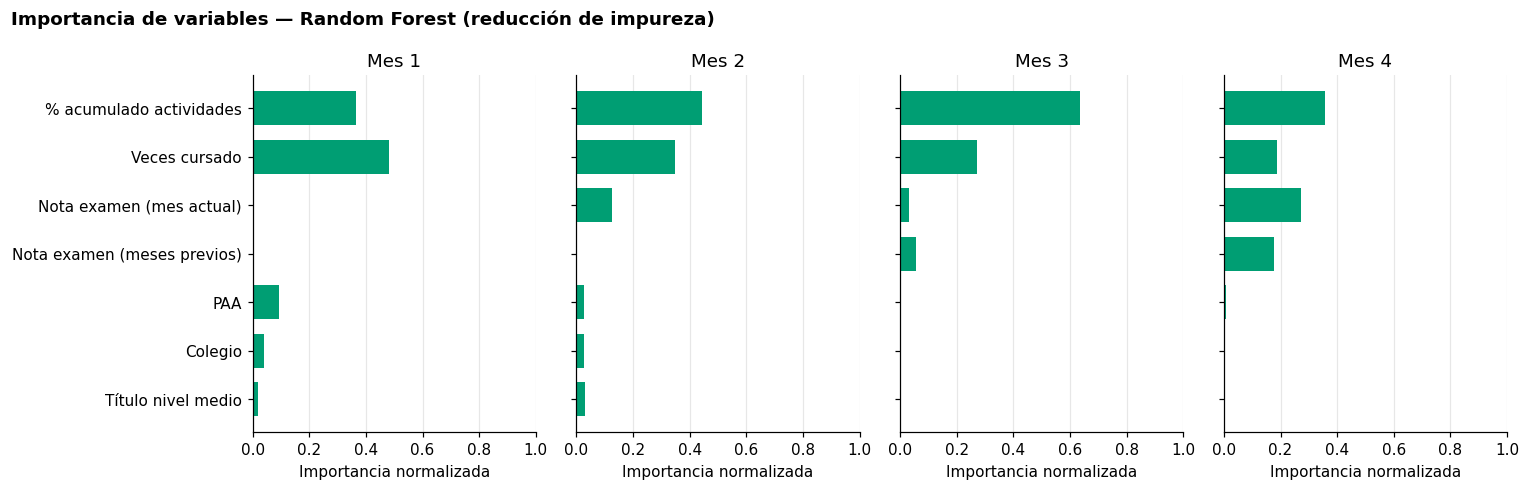

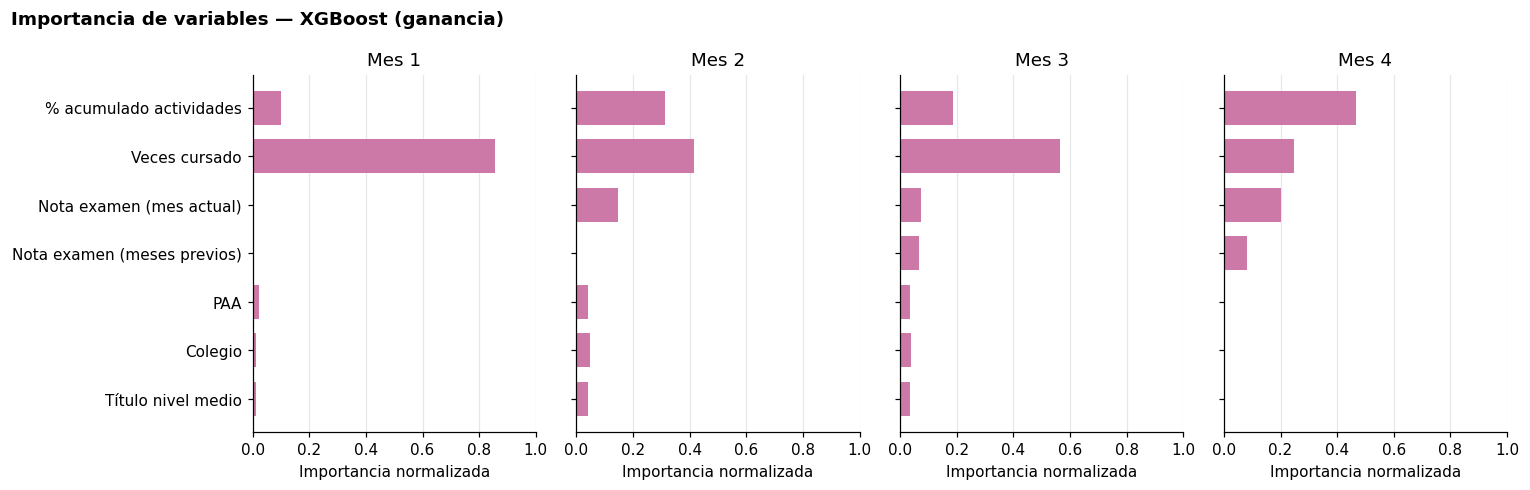

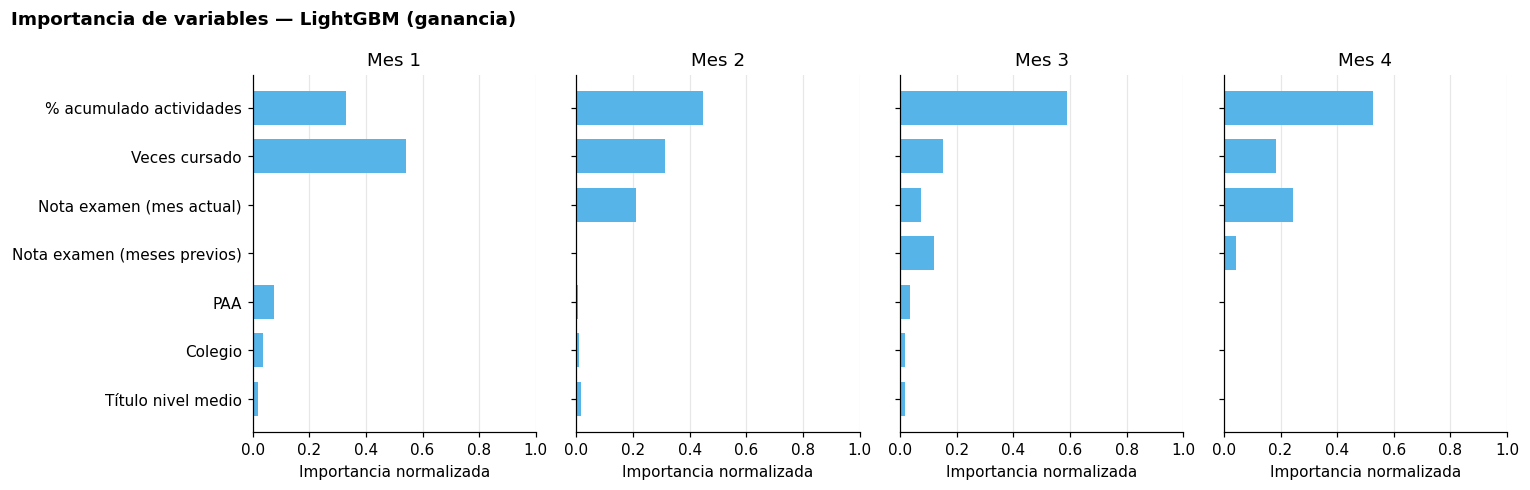

In [33]:
# Importancia de variables por modelo
MESES = sorted(imp["mes"].unique())
ORDEN_VARIABLES = (imp.groupby("Variable")["importancia_norm"].mean()
                   .sort_values(ascending=True).index.tolist())   # mismo orden en todas las gráficas

def importancia_modelo(modelo, guardar=True):
    """Grafica la importancia de variables de un modelo con un panel por mes"""
    d = imp[imp["Modelo"] == modelo]
    fig, axes = plt.subplots(1, len(MESES), figsize=(14, 4.5), sharey=True, sharex=True)
    for ax, mes in zip(axes, MESES):
        s = (d[d["mes"] == mes].set_index("Variable")["importancia_norm"]
             .reindex(ORDEN_VARIABLES))
        disponible = s.notna()
        ax.barh(np.arange(len(ORDEN_VARIABLES))[disponible], s[disponible],
                color=COLORES_MODELO[modelo], height=0.7)
        ax.set_yticks(np.arange(len(ORDEN_VARIABLES)))
        ax.set_yticklabels(ORDEN_VARIABLES)
        ax.set_title(f"Mes {mes}")
        ax.set_xlim(0, 1)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Importancia normalizada")
    fig.suptitle(f"Importancia de variables — {modelo} ({ETIQUETA_TIPO.get(TIPO_IMP[modelo], TIPO_IMP[modelo])})",
                 fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    if guardar:
        nombre = [k for k, v in NOMBRES_MODELO.items() if v == modelo][0]
        fig.savefig(os.path.join(RUTA_FIGS, f"importancia_{nombre}.png"))
    plt.show()

for modelo in ORDEN_MODELOS:
    importancia_modelo(modelo)

### 3.2 Importancia general (todos los modelos y meses)
Promedio de la importancia normalizada sobre las 20 combinaciones modelo × mes.
Si una variable no existe en un mes (p. ej. la nota de examen en el mes 1) cuenta como 0,
porque ese modelo no pudo usarla. La barra de error es la desviación estándar.

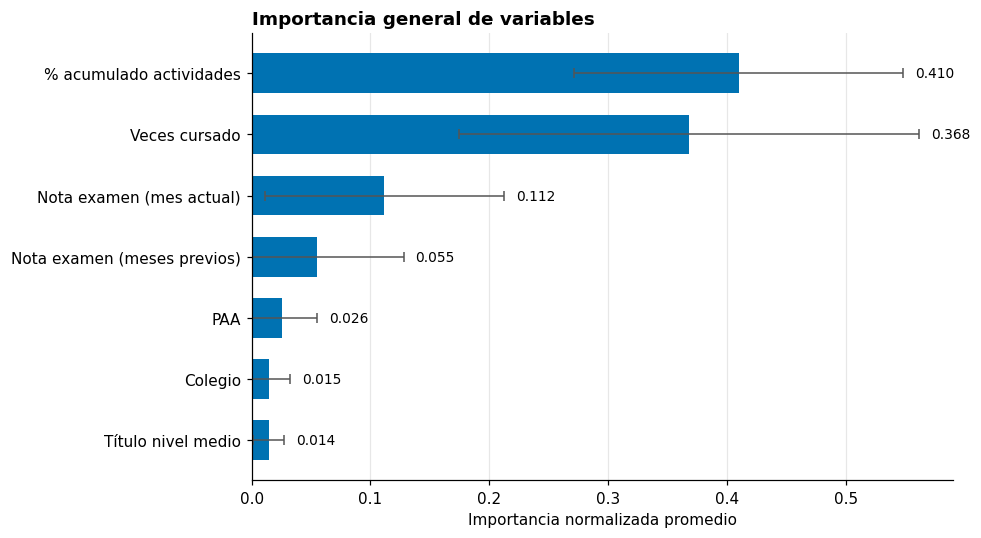

,mean,std
Variable,,
% acumulado actividades,0.4101,0.1386
Veces cursado,0.3680,0.1936
Nota examen (mes actual),0.1118,0.1005
Nota examen (meses previos),0.0552,0.0728
PAA,0.0256,0.0298
Colegio,0.0150,0.0174
Título nivel medio,0.0143,0.0133


In [34]:
# Rellenar con 0 las variables ausentes en cada modelo-mes
completo = (imp.pivot_table(index=["Modelo", "mes"], columns="Variable",
                            values="importancia_norm", fill_value=0)
            .stack().rename("importancia_norm").reset_index())

general = (completo.groupby("Variable")["importancia_norm"]
           .agg(["mean", "std"]).sort_values("mean"))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(general.index, general["mean"], xerr=general["std"],
        color="#0072B2", height=0.65, error_kw=dict(ecolor="#555", capsize=3, lw=1))
for y, (v, sd) in enumerate(zip(general["mean"], general["std"])):
    ax.text(v + sd + 0.01, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Importancia normalizada promedio")
ax.set_xlim(0, None)
ax.grid(axis="y", visible=False)
ax.set_title("Importancia general de variables", fontweight="bold", loc="left")
fig.tight_layout()
fig.savefig(os.path.join(RUTA_FIGS, "importancia_general.png"))
plt.show()

display(general.sort_values("mean", ascending=False).round(4))

### 3.3 Mapa de calor: importancia promedio por modelo y por mes

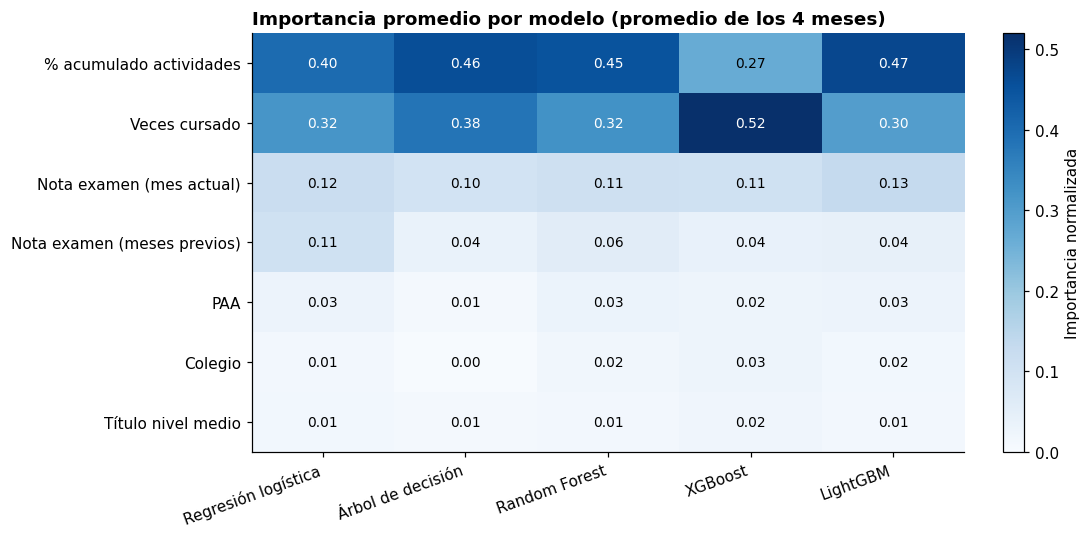

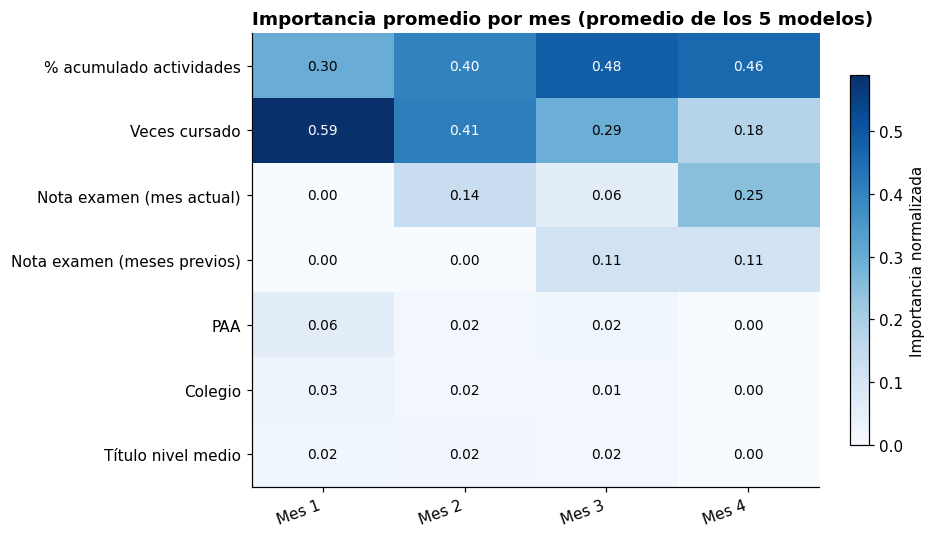

In [35]:
# Mapas de calor de importancia por modelo y por mes
def heatmap(df, titulo, archivo, xlabel):
    """Grafica un mapa de calor de importancias y lo guarda"""
    fig, ax = plt.subplots(figsize=(1.4 * df.shape[1] + 3, 0.5 * df.shape[0] + 1.5))
    im = ax.imshow(df.values, cmap="Blues", vmin=0, vmax=df.values.max(), aspect="auto")
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns, rotation=20, ha="right")
    ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index)
    ax.grid(False)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.55 * df.values.max() else "black")
    ax.set_xlabel(xlabel)
    ax.set_title(titulo, fontweight="bold", loc="left")
    fig.colorbar(im, ax=ax, fraction=0.03, label="Importancia normalizada")
    fig.tight_layout()
    fig.savefig(os.path.join(RUTA_FIGS, archivo))
    plt.show()

orden_desc = general.sort_values("mean", ascending=False).index

por_modelo = (completo.pivot_table(index="Variable", columns="Modelo", values="importancia_norm", aggfunc="mean")
              .loc[orden_desc, ORDEN_MODELOS])
heatmap(por_modelo, "Importancia promedio por modelo (promedio de los 4 meses)",
        "heatmap_importancia_modelo.png", "")

por_mes = (completo.pivot_table(index="Variable", columns="mes", values="importancia_norm", aggfunc="mean")
           .loc[orden_desc])
por_mes.columns = [f"Mes {m}" for m in por_mes.columns]
heatmap(por_mes, "Importancia promedio por mes (promedio de los 5 modelos)",
        "heatmap_importancia_mes.png", "")

**Conclusión:** en promedio, las variables más importantes son el **porcentaje acumulado en actividades** (0.41) y el **número de intento** (0.37), seguidas de la nota del examen del mes actual (0.11). El PAA, el colegio y el título de nivel medio aportan poco (< 0.03 cada uno).